# Renewable power capacity by country: the Middle East first, then the world

**How much renewable power capacity does each Middle East economy have, how fast did it grow in 2025, and how does the region compare with the rest of the world?**

Data: IRENA, *Renewable Capacity Statistics 2026*, table "Total renewable energy", installed capacity in megawatts at the end of each year from 2016 to 2025. Figures printed in the IRENA press release and in three news reports are used as a second reading.

Author: Toheeb Adeboye

## 1. Load the raw files

The IRENA table was read twice, in two separate passes. Each pass is kept as its own file. Reading B has 31 rows (the world, ten regional rows and 20 countries). Reading A has the 22 rows it shares with B.

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # run from the project folder
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 180)
YEARS = [str(y) for y in range(2016, 2026)]
a = pd.read_csv("data/raw/irena_2026_total_renewable_reading_a.csv")
b = pd.read_csv("data/raw/irena_2026_total_renewable_reading_b.csv")
sec = pd.read_csv("data/raw/secondary_reports.csv")
print("reading A rows:", len(a), "| reading B rows:", len(b), "| secondary figures:", len(sec))
b.head(12)

reading A rows: 22 | reading B rows: 31 | secondary figures: 42


,label_in_source,row_type,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,World,world,2020792,2186943,2357537,2541486,2810899,3077120,3379389,3872829,4457340,5149280
1,Africa,region,37065,41461,45755,48229,51440,53574,58774,65478,71091,82371
2,Asia,region,813285,920341,1025161,1125186,1301574,1456357,1630832,1961722,2377266,2890615
3,C America + Carib,region,13201,14033,14984,15889,16428,17070,17626,18694,19492,21265
4,Eurasia,region,90437,95221,99362,103065,109235,114852,118432,128956,133058,141409
5,Europe,region,487975,511583,536263,573354,606691,649383,706769,782747,857563,934334
6,European Union,subtotal,387390,404364,422166,449529,477283,514661,565469,635960,709457,779443
7,Middle East,region,16718,17085,18650,21437,23627,25902,30981,37863,43778,56446
8,N America,region,331180,347620,365955,390522,422331,460822,490072,525998,571632,613690
9,Oceania,region,27009,29161,34393,40279,47024,52331,58543,61574,70322,76383


## 2. Data checks

Row count, missing values, duplicates, value range, and whether the two readings agree.

In [2]:
print("missing values:", int(a[YEARS].isna().sum().sum()), int(b[YEARS].isna().sum().sum()))
print("duplicate labels:", int(a.label_requested.duplicated().sum()), int(b.label_in_source.duplicated().sum()))
print("smallest and largest value in reading B:", int(b[YEARS].min().min()), int(b[YEARS].max().max()))
print("rows by type:", b.row_type.value_counts().to_dict())
rename = {"Iran": "Iran IR", "Syria": "Syrian AR", "United Arab Emirates": "United Arab Em", "Turkey": "Türkiye"}
a["label_in_source"] = a.label_requested.replace(rename)
m = a.merge(b, on="label_in_source", suffixes=("_a", "_b"))
cells_compared = len(m) * len(YEARS)
cells_equal = sum(int((m[y + "_a"] == m[y + "_b"]).sum()) for y in YEARS)
print("rows in both readings:", len(m), "| cells compared:", cells_compared, "| cells equal:", cells_equal)
assert cells_equal == cells_compared == 220

missing values: 0 0
duplicate labels: 0 0
smallest and largest value in reading B: 2 5149280
rows by type: {'country': 20, 'region': 9, 'world': 1, 'subtotal': 1}
rows in both readings: 22 | cells compared: 220 | cells equal: 220


## 3. Do the printed totals equal the sum of their parts?

IRENA prints a Middle East total above 14 countries, and a world total above nine regions. A misread digit in any country or region would open a gap. Every figure is rounded to a whole megawatt, so gaps of 1 or 2 MW are rounding.

In [3]:
idx = b.set_index("label_in_source")[YEARS]
me14 = ["Bahrain", "Iran IR", "Iraq", "Israel", "Jordan", "Kuwait", "Lebanon", "Oman", "Palestine", "Qatar",
        "Saudi Arabia", "Syrian AR", "United Arab Em", "Yemen"]
regions9 = ["Africa", "Asia", "C America + Carib", "Eurasia", "Europe", "Middle East", "N America", "Oceania",
            "S America"]
chk = pd.DataFrame({"middle_east_printed": idx.loc["Middle East"], "sum_of_14_countries": idx.loc[me14].sum(),
                    "world_printed": idx.loc["World"], "sum_of_9_regions": idx.loc[regions9].sum()})
chk["gap_middle_east_mw"] = chk.middle_east_printed - chk.sum_of_14_countries
chk["gap_world_mw"] = chk.world_printed - chk.sum_of_9_regions
assert chk.gap_middle_east_mw.abs().max() <= 3 and chk.gap_world_mw.abs().max() <= 5
chk

,middle_east_printed,sum_of_14_countries,world_printed,sum_of_9_regions,gap_middle_east_mw,gap_world_mw
2016,16718,16717,2020792,2020790,1,2
2017,17085,17084,2186943,2186942,1,1
2018,18650,18648,2357537,2357537,2,0
2019,21437,21435,2541486,2541485,2,1
2020,23627,23626,2810899,2810898,1,1
2021,25902,25900,3077120,3077120,2,0
2022,30981,30981,3379389,3379387,0,2
2023,37863,37862,3872829,3872830,1,-1
2024,43778,43779,4457340,4457341,-1,-1
2025,56446,56447,5149280,5149280,-1,0


## 4. Build the tidy table

One row per country, group or region per year, with the change from the year before. The 20 economies are grouped into the four sub-regions used across this portfolio.

In [4]:
SUB = {"Gulf": ["Bahrain", "Kuwait", "Oman", "Qatar", "Saudi Arabia", "United Arab Em"],
       "Levant and Iraq": ["Iraq", "Israel", "Jordan", "Lebanon", "Palestine", "Syrian AR"],
       "Iran, Turkey and Yemen": ["Iran IR", "Türkiye", "Yemen"],
       "North Africa": ["Algeria", "Egypt", "Libya", "Morocco", "Tunisia"]}
NAME = {"United Arab Em": "United Arab Emirates", "Syrian AR": "Syria", "Iran IR": "Iran", "Türkiye": "Turkey"}
c = b[b.row_type == "country"].copy()
c["country"] = c.label_in_source.replace(NAME)
c["sub_region"] = c.label_in_source.map({l: s for s, ls in SUB.items() for l in ls})
c = c.set_index("country")
c[YEARS] = c[YEARS].astype(int)
c["added_2025_mw"] = c["2025"] - c["2024"]
c["growth_2025_pct"] = ((c["2025"] / c["2024"] - 1) * 100).round(1)
print("economies:", len(c), "|", c.sub_region.value_counts().to_dict())
c[["sub_region", "2016", "2024", "2025", "added_2025_mw", "growth_2025_pct"]].sort_values("added_2025_mw", ascending=False)

economies: 20 | {'Gulf': 6, 'Levant and Iraq': 6, 'North Africa': 5, 'Iran, Turkey and Yemen': 3}


,sub_region,2016,2024,2025,added_2025_mw,growth_2025_pct
country,,,,,,
Turkey,"Iran, Turkey and Yemen",34446,69087,76300,7213,10.4
Saudi Arabia,Gulf,24,6601,12332,5731,86.8
Israel,Levant and Iraq,966,6006,7763,1757,29.3
Egypt,North Africa,3681,7716,9258,1542,20.0
United Arab Emirates,Gulf,136,6853,7907,1054,15.4
Iran,"Iran, Turkey and Yemen",10783,12961,13963,1002,7.7
Oman,Gulf,2,722,1722,1000,138.5
Qatar,Gulf,24,824,1699,875,106.2
Syria,Levant and Iraq,1501,3108,3806,698,22.5


## 5. The Gulf, 2016 to 2025

In [5]:
gulf = c[c.sub_region == "Gulf"]
gulf_total = gulf[YEARS].sum()
print("Gulf total by year (MW):")
print(gulf_total.to_string())
g16, g24, g25 = int(gulf_total["2016"]), int(gulf_total["2024"]), int(gulf_total["2025"])
print()
print(f"2016: {g16:,} MW | 2024: {g24:,} MW | 2025: {g25:,} MW")
print(f"added in 2025: {g25 - g24:,} MW ({(g25 / g24 - 1) * 100:.1f}%) | 2025 is {g25 / g16:.1f} times 2016")
sa = gulf.loc["Saudi Arabia"]
print(f"Saudi Arabia: {sa['2024']:,} to {sa['2025']:,} MW, +{sa.added_2025_mw:,} MW ({sa.growth_2025_pct}%), "
      f"{sa.added_2025_mw / (g25 - g24) * 100:.1f}% of what the Gulf added")
gulf[["2016", "2020", "2024", "2025", "added_2025_mw", "growth_2025_pct"]].sort_values("2025", ascending=False)

Gulf total by year (MW):
2016      217
2017      455
2018      791
2019     2255
2020     3057
2021     3793
2022     6137
2023    10631
2024    15183
2025    23889

2016: 217 MW | 2024: 15,183 MW | 2025: 23,889 MW
added in 2025: 8,706 MW (57.3%) | 2025 is 110.1 times 2016
Saudi Arabia: 6,601 to 12,332 MW, +5,731 MW (86.8%), 65.8% of what the Gulf added


,2016,2020,2024,2025,added_2025_mw,growth_2025_pct
country,,,,,,
Saudi Arabia,24,412,6601,12332,5731,86.8
United Arab Emirates,136,2334,6853,7907,1054,15.4
Oman,2,179,722,1722,1000,138.5
Qatar,24,24,824,1699,875,106.2
Bahrain,7,11,69,115,46,66.7
Kuwait,24,97,114,114,0,0.0


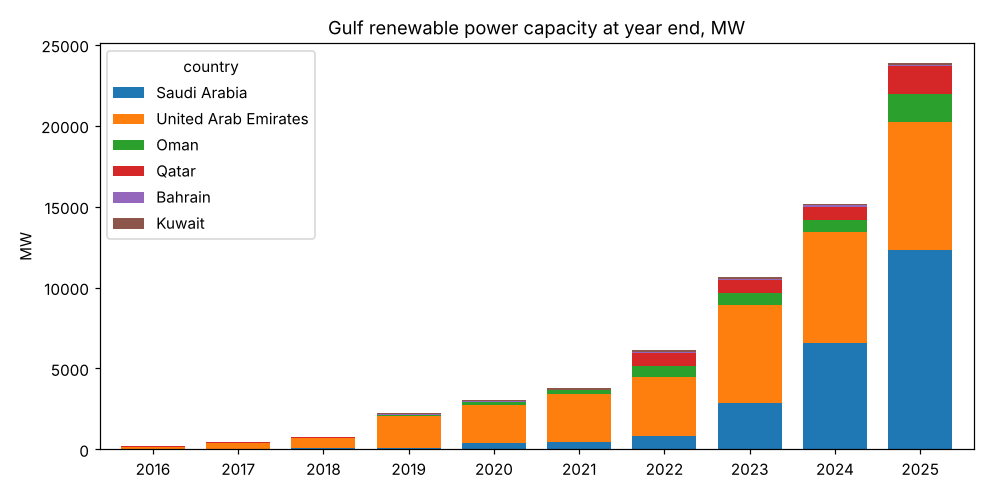

In [6]:
order = ["Saudi Arabia", "United Arab Emirates", "Oman", "Qatar", "Bahrain", "Kuwait"]
ax = gulf.loc[order, YEARS].T.plot(kind="bar", stacked=True, figsize=(9, 4.5), width=0.75)
ax.set_ylabel("MW"); ax.set_title("Gulf renewable power capacity at year end, MW")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 6. The 20 economies by sub-region

In [7]:
subs = c.groupby("sub_region")[["2016", "2024", "2025"]].sum().loc[list(SUB)]
subs["added_2025_mw"] = subs["2025"] - subs["2024"]
subs["growth_2025_pct"] = ((subs["2025"] / subs["2024"] - 1) * 100).round(1)
total20 = c[["2016", "2024", "2025"]].sum()
print(f"20 economies: {total20['2024']:,} to {total20['2025']:,} MW, "
      f"+{total20['2025'] - total20['2024']:,} MW ({(total20['2025'] / total20['2024'] - 1) * 100:.1f}%)")
print(f"Turkey's share of the 20-economy total in 2025: {c.loc['Turkey', '2025'] / total20['2025'] * 100:.1f}%")
print("no change recorded in 2025:", ", ".join(c[c.added_2025_mw == 0].index))
subs

20 economies: 126,936 to 148,672 MW, +21,736 MW (17.1%)
Turkey's share of the 20-economy total in 2025: 51.3%
no change recorded in 2025: Algeria, Jordan, Kuwait


,2016,2024,2025,added_2025_mw,growth_2025_pct
sub_region,,,,,
Gulf,217,15183,23889,8706,57.3
Levant and Iraq,5636,15232,18139,2907,19.1
"Iran, Turkey and Yemen",45310,82451,90719,8268,10.0
North Africa,6943,14070,15925,1855,13.2


## 7. Regions of the world, as IRENA defines them

IRENA's Middle East has 14 countries. North Africa is counted in Africa and Turkey in Eurasia, so the regional rows below are not the same group as the 20 economies above.

In [8]:
r = b[b.row_type.isin(["region", "world"])].set_index("label_in_source")[["2016", "2024", "2025"]].astype(int)
r["added_2025_mw"] = r["2025"] - r["2024"]
r["growth_2025_pct"] = ((r["2025"] / r["2024"] - 1) * 100).round(1)
r["multiple_of_2016"] = (r["2025"] / r["2016"]).round(1)
r["share_of_world_2025_pct"] = (r["2025"] / r.loc["World", "2025"] * 100).round(2)
r = r.sort_values("growth_2025_pct", ascending=False)
me = r.loc["Middle East"]
print(f"Middle East: {me['2024']:,.0f} to {me['2025']:,.0f} MW, +{me.added_2025_mw:,.0f} MW, {me.growth_2025_pct}%")
print(f"Saudi Arabia's share of what the IRENA Middle East added: {sa.added_2025_mw / me.added_2025_mw * 100:.1f}%")
assert r.drop("World").growth_2025_pct.idxmax() == "Middle East"
r

Middle East: 43,778 to 56,446 MW, +12,668 MW, 28.9%
Saudi Arabia's share of what the IRENA Middle East added: 45.2%


,2016,2024,2025,added_2025_mw,growth_2025_pct,multiple_of_2016,share_of_world_2025_pct
label_in_source,,,,,,,
Middle East,16718,43778,56446,12668,28.9,3.4,1.10
Asia,813285,2377266,2890615,513349,21.6,3.6,56.14
Africa,37065,71091,82371,11280,15.9,2.2,1.60
World,2020792,4457340,5149280,691940,15.5,2.5,100.00
C America + Carib,13201,19492,21265,1773,9.1,1.6,0.41
Europe,487975,857563,934334,76771,9.0,1.9,18.14
Oceania,27009,70322,76383,6061,8.6,2.8,1.48
N America,331180,571632,613690,42058,7.4,1.9,11.92
Eurasia,90437,133058,141409,8351,6.3,1.6,2.75


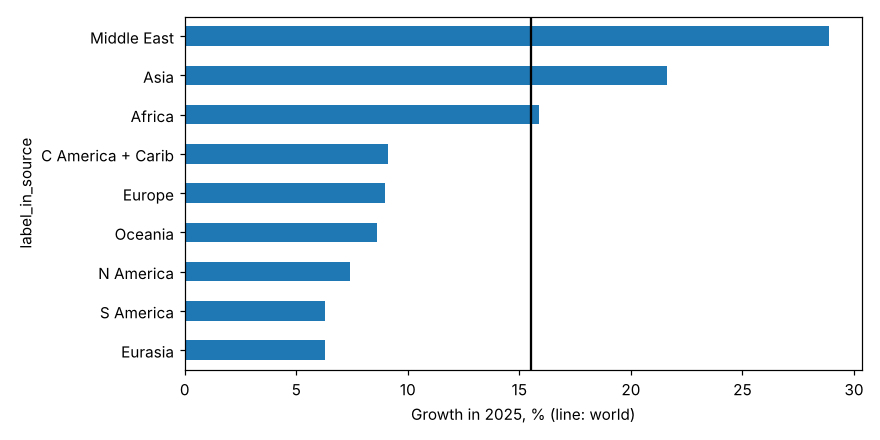

In [9]:
ax = r.drop("World").growth_2025_pct.sort_values().plot(kind="barh", figsize=(8, 4))
ax.axvline(r.loc["World", "growth_2025_pct"], color="black"); ax.set_xlabel("Growth in 2025, % (line: world)")
plt.tight_layout(); plt.show()

## 8. Figures printed elsewhere

The IRENA press release, a regional business newsletter and a trade publication print some of the same figures, rounded. A report agrees when it is within one unit of its last printed digit. The Arab Energy Organisation is a separate compiler and gives capacity added in 2025 for seven countries.

In [10]:
col = {"capacity_2025": "2025", "capacity_2024": "2024"}
full = pd.concat([c[["2024", "2025"]], r.rename(index={"N America": "North America"})[["2024", "2025"]]])
full.index = [NAME.get(i, i) for i in full.index]
rows = []
for _, s in sec.iterrows():
    v24, v25 = full.loc[s.entity, "2024"], full.loc[s.entity, "2025"]
    if s.measure == "growth_2025_pct":
        val = (v25 / v24 - 1) * 100
    else:
        val = (v25 - v24) if s.measure == "added_2025" else full.loc[s.entity, col[s.measure]]
        val = val / (1000 if s.unit == "GW" else 1)
    rows.append((s.source, s.entity, s.measure, s.published_value, s.unit, round(float(val), 3),
                 "agrees" if abs(val - s.published_value) < 10 ** (-int(s.decimals)) else "differs"))
checks = pd.DataFrame(rows, columns=["source", "entity", "measure", "published", "unit", "irena_table", "status"])
print(checks.status.value_counts().to_dict())
print(checks.groupby("source").status.value_counts().to_string())
checks[checks.status == "differs"]

{'agrees': 41, 'differs': 1}
source                                                     status 
Arab Energy Organisation annual report (Energetica India)  agrees      6
                                                           differs     1
Energetica India (11 April 2026)                           agrees      3
Enterprise (19 April 2026)                                 agrees     21
IRENA press release (Zawya)                                agrees     11


,source,entity,measure,published,unit,irena_table,status
37,Arab Energy Organisation annual report (Energetica India),United Arab Emirates,added_2025,1.3,GW,1.054,differs


## 9. Do these figures match the build script output?

`scripts/build_data.py` writes the processed tables. The figures computed above must equal them.

In [11]:
tidy = pd.read_csv("data/processed/renewable_capacity_tidy.csv")
cs = pd.read_csv("data/processed/country_summary_2025.csv").set_index("country")
gs = pd.read_csv("data/processed/group_summary.csv").set_index("entity")
pc = pd.read_csv("data/processed/secondary_checks.csv")
assert len(tidy) == 350 and len(cs) == 20 and len(gs) == 15
assert (cs.capacity_2025_mw == c["2025"].reindex(cs.index)).all()
assert (cs.added_2025_mw == c.added_2025_mw.reindex(cs.index)).all()
assert (cs.growth_2025_pct == c.growth_2025_pct.reindex(cs.index)).all()
assert gs.loc["Gulf", "capacity_2016_mw"] == g16 == 217
assert gs.loc["Gulf", "capacity_2025_mw"] == g25 == 23889
assert gs.loc["Gulf", "added_2025_mw"] == g25 - g24 == 8706
assert gs.loc["Middle East", "growth_2025_pct"] == me.growth_2025_pct == 28.9
assert gs.loc["World", "growth_2025_pct"] == r.loc["World", "growth_2025_pct"] == 15.5
assert gs.loc["Middle East and North Africa (20 economies)", "capacity_2025_mw"] == total20["2025"] == 148672
assert cs.loc["Saudi Arabia", "added_2025_mw"] == 5731 and cs.loc["Saudi Arabia", "growth_2025_pct"] == 86.8
assert (pc.status.values == checks.status.values).all() and (pc.status == "differs").sum() == 1
print("all figures match the processed tables")

all figures match the processed tables
